# Formative User Feedback: Three-round comparative analysis

This notebook combines the exported results from Formative User Feedback (FUF) Rounds 1–3. It examines **observed task duration, performance, adaptive-rule behaviour, music transitions, and data completeness**.

**Purpose.** Use the results to decide whether a five- or six-minute experimental block provides enough usable observations, describe overall performance, and identify implementation questions for the next study phase.

**Interpretation boundary.** Each round has a small formative sample. The analyses describe prototype behaviour and participant performance; they do **not** establish that music caused a change in performance or that one timing is statistically superior.


## Analysis basis and source of truth

- The thesis is used only as the methodological frame for analysing task performance, errors, timing, and adaptation.
- The current application configuration is read from the current `main` branch and is the source of truth for the **present** rule settings.
- Historical rounds are described from their exports. Their exported build/config identifiers are retained, because their settings may differ from the current configuration.
- `interrupted_restart` rows are excluded from performance summaries, but are counted in the data-quality section.


In [1]:
from pathlib import Path
from io import BytesIO
import json
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

# Update these three paths only if you move the source archives.
ITERATION_ARCHIVES = {
    "Round 1": Path("/Users/zi/Documents/GitHub/TunedIn-Web/feedback-files/results/iterative-1.zip"),
    "Round 2": Path("/Users/zi/Documents/GitHub/TunedIn-Web/feedback-files/results/iterative-2.zip"),
    "Round 3": Path("/Users/zi/Documents/GitHub/TunedIn-Web/feedback-files/results/iterative-3.zip"),
}
CURRENT_CONFIG_PATH = Path("/Users/zi/.codex/.chatgpt-projects/g-p-6aafa841d5ec819188af84ee01b0d22a/TunedIn-Web-main-f0a0383/config/study.json")

for round_name, path in ITERATION_ARCHIVES.items():
    if not path.exists():
        raise FileNotFoundError(f"{round_name}: archive not found at {path}")
if not CURRENT_CONFIG_PATH.exists():
    raise FileNotFoundError(f"Current study configuration not found at {CURRENT_CONFIG_PATH}")

current_config = json.loads(CURRENT_CONFIG_PATH.read_text())
print("Current app build:", current_config["buildVersion"])
print("Current adaptive rules:", current_config["adaptiveRules"])


Current app build: fuf-iteration-3.0.1
Current adaptive rules: {'rollingWindowSeconds': 60, 'evaluationIntervalSeconds': 30, 'minimumRecordCount': 3, 'reducedIlMultiplier': 1.2, 'reducedFpedMultiplier': 1.2, 'reducedErrorRate': 0.15, 'elevatedIlMultiplier': 0.95, 'elevatedFpedMultiplier': 0.95, 'elevatedErrorRate': 0.1}


## 1. Load all participant exports

The loader supports either form used by the three rounds:

1. an archive containing participant result ZIPs; or
2. an archive containing multiple participant export folders directly.

It ignores macOS metadata files and retains the source archive and round with every row.


In [2]:
TABLES = ("blocks", "records", "decisions", "transitions", "tracks")

def usable_names(archive):
    return [name for name in archive.namelist()
            if not name.startswith("__MACOSX/") and not name.rsplit("/", 1)[-1].startswith("._")]

def member_in_same_folder(names, folder, filename):
    expected = f"{folder}/{filename}" if folder else filename
    if expected in names:
        return expected
    return None

def read_export_zip(zip_bytes, round_name, source_name):
    """Read every complete participant-export folder inside one ZIP."""
    bundles = []
    with zipfile.ZipFile(BytesIO(zip_bytes)) as archive:
        names = usable_names(archive)
        session_members = [name for name in names if name == "session.json" or name.endswith("/session.json")]
        for session_member in session_members:
            folder = session_member.rsplit("/", 1)[0] if "/" in session_member else ""
            session = json.loads(archive.read(session_member))
            bundle = {"round": round_name, "source_archive": source_name, "session": session}
            for table in TABLES:
                member = member_in_same_folder(names, folder, f"{table}.csv")
                bundle[table] = (pd.read_csv(BytesIO(archive.read(member))) if member else pd.DataFrame())
            bundles.append(bundle)
    return bundles

def load_iteration_archive(round_name, path):
    with zipfile.ZipFile(path) as archive:
        names = usable_names(archive)
        nested_zips = [name for name in names if name.lower().endswith(".zip")]
        if nested_zips:
            bundles = []
            for member in nested_zips:
                bundles.extend(read_export_zip(archive.read(member), round_name, member))
            return bundles
    # The outer archive itself contains participant export folders.
    return read_export_zip(path.read_bytes(), round_name, path.name)

bundles = []
for round_name, path in ITERATION_ARCHIVES.items():
    bundles.extend(load_iteration_archive(round_name, path))

if not bundles:
    raise ValueError("No participant export folders were found.")

def combine_table(table):
    frames = []
    for bundle in bundles:
        frame = bundle[table].copy()
        if frame.empty:
            continue
        frame["round"] = bundle["round"]
        frame["source_archive"] = bundle["source_archive"]
        frame["session_id"] = bundle["session"].get("id", bundle["session"].get("sessionId"))
        frames.append(frame)
    return pd.concat(frames, ignore_index=True, sort=False) if frames else pd.DataFrame()

sessions = pd.DataFrame([
    {**bundle["session"], "round": bundle["round"], "source_archive": bundle["source_archive"]}
    for bundle in bundles
])
blocks = combine_table("blocks")
records = combine_table("records")
decisions = combine_table("decisions")
transitions = combine_table("transitions")
tracks = combine_table("tracks")

print(f"Participant exports loaded: {len(bundles)}")
print(f"Sessions: {len(sessions)} | Blocks: {len(blocks)} | Records: {len(records)} | Decisions: {len(decisions)} | Transitions: {len(transitions)}")
display(sessions[[c for c in ["round", "participantId", "id", "studyMode", "buildVersion", "configVersion"] if c in sessions.columns]])


Participant exports loaded: 9
Sessions: 9 | Blocks: 26 | Records: 306 | Decisions: 86 | Transitions: 25


,round,participantId,id,studyMode,buildVersion,configVersion
0,Round 1,P003,4e04e8a9-c87f-46a9-8c4a-b5fe98d88cb6,Formative,fuf-iteration-1.0.1,formative-feedback
1,Round 1,P001,881ab526-725c-4d7c-8471-1355ab767a25,Formative,fuf-iteration-1.0.1-timing-1m-2m-6m,formative-feedback
2,Round 1,P002,4cf12525-53fe-4f2e-8a6f-7719f8e9e57f,Formative,fuf-iteration-1.0.1,formative-feedback
3,Round 2,F2-P003,862bc3ed-17ea-46fe-b02c-c831ffce8767,Formative,fuf-iteration-2.0.1,formative-feedback
4,Round 2,P001,d12fcde4-33ad-4208-9996-8cbaff22e38a,Formative,fuf-iteration-2.0.1-timing-1m-2m-5m,formative-feedback
5,Round 2,F2-P002,f688e2ff-59d2-4d66-82d9-e9fbfceac100,Formative,fuf-iteration-2.0.1,formative-feedback
6,Round 3,F3-P002,4e521302-acd9-4000-baef-5e244574cb4a,Formative,fuf-iteration-3.0.1,formative-feedback
7,Round 3,F3-P003,69b61f9b-9856-4a36-89e7-9b91eefefd35,Formative,fuf-iteration-3.0.1,formative-feedback
8,Round 3,P001,75d3d179-bf94-4395-b425-acca671b998c,Formative,fuf-iteration-3.0.1-timing-1m-2m-5m,formative-feedback


## 2. Prepare completed task attempts

The backend can retain an empty row when a timed block is restarted after an interruption. These rows are important audit information, but they do not represent completed task performance. This section separates them before calculating medians, error rates, or throughput.


In [3]:
def numeric(frame, columns):
    frame = frame.copy()
    for column in columns:
        if column in frame.columns:
            frame[column] = pd.to_numeric(frame[column], errors="coerce")
    return frame

blocks = numeric(blocks, [
    "block", "duration_seconds", "records_presented", "validated_records",
    "validated_records_per_minute", "median_il_ms", "median_fped_ms",
    "first_pass_error_rate", "correction_cycles", "configured_practice_seconds",
    "configured_baseline_seconds", "configured_block_seconds",
])
decisions = numeric(decisions, [
    "block", "record_count", "median_il_ms", "median_fped_ms",
    "first_pass_error_rate", "baseline_il_ms", "baseline_fped_ms",
    "window_start_ms", "window_end_ms",
])
transitions = numeric(transitions, ["block", "started_ms", "completed_ms"])

# Older exports predate attempt_status. A missing value therefore means the row is a completed block.
attempt_status = blocks.get("attempt_status", pd.Series("completed", index=blocks.index))
completed_blocks = blocks.loc[attempt_status.isna() | attempt_status.eq("completed")].copy()
restarted_rows = blocks.loc[attempt_status.eq("interrupted_restart")].copy()

for frame in (completed_blocks, decisions, transitions):
    if "participant_id" not in frame.columns and "participantId" in frame.columns:
        frame["participant_id"] = frame["participantId"]

# Block 0 = Practice, 1 = Silent Baseline Calibration, and blocks 2+ are experimental.
completed_blocks["segment"] = completed_blocks["block"].map({0: "Practice", 1: "Silent Baseline"}).fillna("Experimental")
completed_blocks["is_adaptive"] = completed_blocks.get("condition", pd.Series(index=completed_blocks.index, dtype="object")).eq("Adaptive music")
adaptive_blocks = completed_blocks.loc[completed_blocks.is_adaptive].copy()

print("Completed blocks:", len(completed_blocks))
print("Interrupted/restart audit rows:", len(restarted_rows))
display(completed_blocks[[c for c in ["round", "participant_id", "block", "segment", "condition", "duration_seconds", "validated_records", "validated_records_per_minute", "first_pass_error_rate", "attempt_status"] if c in completed_blocks.columns]].sort_values(["round", "participant_id", "block"]))


Completed blocks: 26
Interrupted/restart audit rows: 0


,round,participant_id,block,segment,condition,duration_seconds,validated_records,validated_records_per_minute,first_pass_error_rate,attempt_status
3,Round 1,P001,0,Practice,No music,60,3,3.000,0.333,NaN
4,Round 1,P001,1,Silent Baseline,No music,120,8,4.000,0.000,NaN
5,Round 1,P001,2,Experimental,Adaptive music,360,29,4.833,0.103,NaN
6,Round 1,P002,0,Practice,No music,60,2,2.000,1.000,NaN
7,Round 1,P002,1,Silent Baseline,No music,120,8,4.000,0.000,NaN
8,Round 1,P002,2,Experimental,Adaptive music,360,27,4.500,0.074,NaN
0,Round 1,P003,0,Practice,No music,60,0,0.000,1.000,NaN
1,Round 1,P003,1,Silent Baseline,No music,120,7,3.500,0.000,NaN
2,Round 1,P003,2,Experimental,Adaptive music,360,21,3.500,0.238,NaN
15,Round 2,F2-P002,0,Practice,No music,60,2,2.000,0.500,completed


## 3. Observed timing and adequacy of experimental blocks

This answers the timing question using the **actual completed experimental-block duration**, not the project defaults. A block is considered analytically informative here when it has (a) completed task measures and (b) adaptive decision records. The threshold is descriptive, not a statistical power calculation.

The key comparison is whether five-minute blocks still create repeated adaptive evaluations and usable performance measures while reducing the fatigue/repetition concerns reported in formative feedback.


In [4]:
experimental = completed_blocks.loc[completed_blocks.segment.eq("Experimental")].copy()

round_timing = (experimental.groupby("round", as_index=False)
    .agg(participants=("participant_id", "nunique"),
         completed_experimental_blocks=("block", "size"),
         median_duration_seconds=("duration_seconds", "median"),
         total_experimental_minutes=("duration_seconds", lambda s: s.sum() / 60),
         total_validated_records=("validated_records", "sum"),
         weighted_records_per_minute=("validated_records", lambda s: s.sum() / (experimental.loc[s.index, "duration_seconds"].sum() / 60)),
         blocks_with_measures=("median_il_ms", lambda s: s.notna().sum()))
)
decision_coverage = (decisions.groupby("round", as_index=False)
    .agg(adaptive_decisions=("block", "size"),
         participants_with_decisions=("participant_id", "nunique"),
         median_records_per_window=("record_count", "median"),
         mean_records_per_window=("record_count", "mean")))
round_timing = round_timing.merge(decision_coverage, on="round", how="left")
round_timing["decisions_per_completed_experimental_block"] = (
    round_timing.adaptive_decisions / round_timing.completed_experimental_blocks
)
display(round_timing.round(2))

per_adaptive_block = (decisions.groupby(["round", "participant_id", "block"], as_index=False)
    .agg(decisions=("block", "size"),
         median_records_in_window=("record_count", "median"),
         final_state=("selected_state", "last")))
display(per_adaptive_block.sort_values(["round", "participant_id"]))

five_minute_rows = experimental.loc[experimental.duration_seconds.between(285, 315)]
print(f"Five-minute completed experimental blocks: {len(five_minute_rows)}")
print(f"Their adaptive decisions: {len(decisions.merge(five_minute_rows[["round", "participant_id", "block"]], on=["round", "participant_id", "block"], how="inner"))}")


,round,participants,completed_experimental_blocks,median_duration_seconds,total_experimental_minutes,total_validated_records,weighted_records_per_minute,blocks_with_measures,adaptive_decisions,participants_with_decisions,median_records_per_window,mean_records_per_window,decisions_per_completed_experimental_block
0,Round 1,3,3,360.000,18.000,77,4.280,3,32,3,4.000,4.280,10.670
1,Round 2,3,3,300.000,15.000,58,3.870,3,27,3,4.000,3.930,9.000
2,Round 3,3,3,300.000,15.000,62,4.130,3,27,3,4.000,4.150,9.000


,round,participant_id,block,decisions,median_records_in_window,final_state
0,Round 1,P001,2,11,5.000,reduced
1,Round 1,P002,2,10,4.000,baseline
2,Round 1,P003,2,11,4.000,baseline
3,Round 2,F2-P002,2,9,4.000,reduced
4,Round 2,F2-P003,2,9,2.000,reduced
5,Round 2,P001,2,9,5.000,elevated
6,Round 3,F3-P002,2,9,4.000,elevated
7,Round 3,F3-P003,2,9,3.000,elevated
8,Round 3,P001,2,9,5.000,baseline


Five-minute completed experimental blocks: 6
Their adaptive decisions: 54


### Timing interpretation

Use the printed values above with the following decision rule:

- If completed five-minute blocks repeatedly yield multiple adaptive evaluations, performance measures, and state selections, five minutes is operationally adequate for this prototype.
- Six-minute Round 1 data are still useful as a comparison, but a longer duration is not automatically better if feedback indicates repetition or fatigue.
- Do not generalise this small formative sample into a final statistical duration. Confirm the selected duration in a pilot with the intended sample and analysis plan.


## 4. Overall task performance

Performance is reported separately for Practice, Silent Baseline, and the experimental Adaptive block. Median initiation latency (IL) and first-pass entry duration (FPED) are in milliseconds; lower values mean faster responding. First-pass error rate is the share of records whose first submission was incorrect.

The summary uses a weighted throughput value: total validated records divided by total completed minutes. This avoids giving a short block the same weight as a longer block.


In [5]:
performance_by_round = (completed_blocks.groupby(["round", "segment"], as_index=False)
    .agg(participants=("participant_id", "nunique"),
         completed_blocks=("block", "size"),
         total_validated_records=("validated_records", "sum"),
         total_minutes=("duration_seconds", lambda s: s.sum() / 60),
         median_il_ms=("median_il_ms", "median"),
         median_fped_ms=("median_fped_ms", "median"),
         median_first_pass_error_rate=("first_pass_error_rate", "median")))
performance_by_round["weighted_records_per_minute"] = (
    performance_by_round.total_validated_records / performance_by_round.total_minutes
)
display(performance_by_round.round(3))

adaptive_performance = (adaptive_blocks.groupby(["round", "participant_id"], as_index=False)
    .agg(duration_seconds=("duration_seconds", "sum"),
         validated_records=("validated_records", "sum"),
         records_per_minute=("validated_records_per_minute", "mean"),
         median_il_ms=("median_il_ms", "median"),
         median_fped_ms=("median_fped_ms", "median"),
         first_pass_error_rate=("first_pass_error_rate", "mean")))
display(adaptive_performance.sort_values(["round", "participant_id"]).round(3))

baseline = completed_blocks.loc[completed_blocks.segment.eq("Silent Baseline")]
comparison = baseline.merge(adaptive_blocks, on=["round", "participant_id"], suffixes=("_baseline", "_adaptive"))
if not comparison.empty:
    comparison["throughput_change_pct"] = 100 * (comparison.validated_records_per_minute_adaptive / comparison.validated_records_per_minute_baseline - 1)
    comparison["error_change_pp"] = 100 * (comparison.first_pass_error_rate_adaptive - comparison.first_pass_error_rate_baseline)
    display(comparison[["round", "participant_id", "throughput_change_pct", "error_change_pp", "median_il_ms_baseline", "median_il_ms_adaptive", "median_fped_ms_baseline", "median_fped_ms_adaptive"]].round(2))
else:
    print("No complete baseline/adaptive pairs were available for this comparison.")


,round,segment,participants,completed_blocks,total_validated_records,total_minutes,median_il_ms,median_fped_ms,median_first_pass_error_rate,weighted_records_per_minute
0,Round 1,Experimental,3,3,77,18.000,"1,463.700","10,344.500",0.103,4.278
1,Round 1,Practice,3,3,5,3.000,"2,448.000","13,542.600",1.000,1.667
2,Round 1,Silent Baseline,3,3,23,6.000,"1,357.150","12,541.950",0.000,3.833
3,Round 2,Experimental,3,3,58,15.000,"1,583.600","11,538.800",0.083,3.867
4,Round 2,Practice,3,3,3,3.000,"2,268.850","14,837.600",0.500,1.000
5,Round 2,Silent Baseline,3,3,21,6.000,"2,018.050","12,341.900",0.000,3.500
6,Round 3,Experimental,3,3,62,15.000,"1,514.000","12,835.900",0.080,4.133
7,Round 3,Practice,2,2,7,2.000,"2,235.925","12,315.350",0.250,3.500
8,Round 3,Silent Baseline,3,3,24,6.000,"1,965.300","13,468.200",0.143,4.000


,round,participant_id,duration_seconds,validated_records,records_per_minute,median_il_ms,median_fped_ms,first_pass_error_rate
0,Round 1,P001,360,29,4.833,"1,310.000","9,619.000",0.103
1,Round 1,P002,360,27,4.500,"1,463.700","10,344.500",0.074
2,Round 1,P003,360,21,3.500,"1,848.600","12,366.300",0.238
3,Round 2,F2-P002,300,19,3.800,"1,583.600","11,538.800",0.158
4,Round 2,F2-P003,300,12,2.400,"2,797.800","18,962.000",0.083
5,Round 2,P001,300,27,5.400,"1,199.000","8,941.000",0.074
6,Round 3,F3-P002,300,20,4.000,"1,514.000","12,835.900",0.050
7,Round 3,F3-P003,300,17,3.400,"1,559.900","14,114.400",0.235
8,Round 3,P001,300,25,5.000,"1,069.000","8,888.000",0.080


,round,participant_id,throughput_change_pct,error_change_pp,median_il_ms_baseline,median_il_ms_adaptive,median_fped_ms_baseline,median_fped_ms_adaptive
0,Round 1,P003,0.000,23.810,"1,394.300","1,848.600","15,157.100","12,366.300"
1,Round 1,P001,20.830,10.340,"1,310.500","1,310.000","11,891.500","9,619.000"
2,Round 1,P002,12.500,7.410,"1,357.150","1,463.700","12,541.950","10,344.500"
3,Round 2,F2-P003,20.000,8.330,"2,786.850","2,797.800","25,041.500","18,962.000"
4,Round 2,P001,20.000,7.410,"1,272.000","1,199.000","10,600.000","8,941.000"
5,Round 2,F2-P002,-5.000,15.790,"2,018.050","1,583.600","12,341.900","11,538.800"
6,Round 3,F3-P002,14.290,-9.290,"1,965.300","1,514.000","13,468.200","12,835.900"
7,Round 3,F3-P003,13.330,-26.470,"2,156.000","1,559.900","13,796.250","14,114.400"
8,Round 3,P001,-9.090,8.000,"1,189.000","1,069.000","8,952.000","8,888.000"


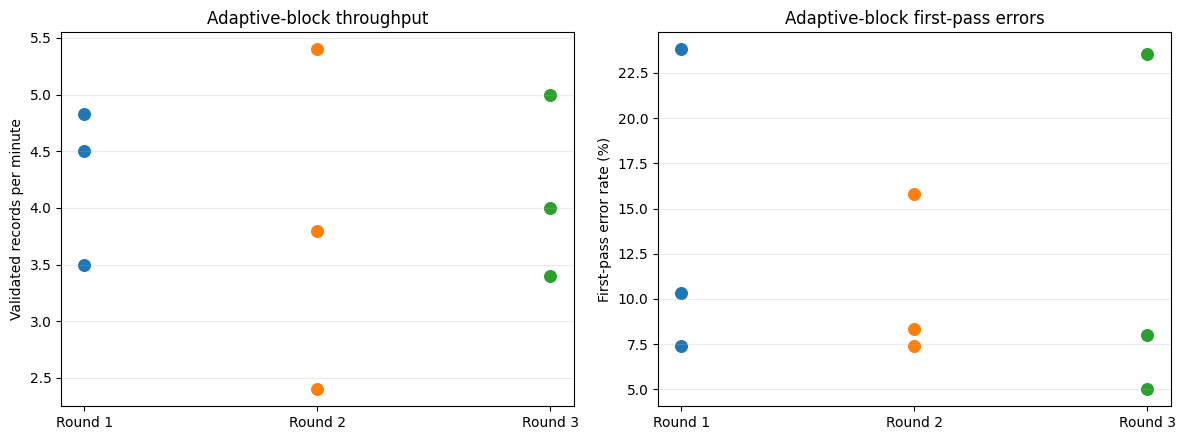

In [6]:
# Visual overview of adaptive-block performance. Small N: every dot is one participant.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for round_name, group in adaptive_performance.groupby("round", sort=False):
    axes[0].scatter([round_name] * len(group), group["records_per_minute"], s=70, label=round_name)
    axes[1].scatter([round_name] * len(group), 100 * group["first_pass_error_rate"], s=70, label=round_name)
axes[0].set_title("Adaptive-block throughput")
axes[0].set_ylabel("Validated records per minute")
axes[1].set_title("Adaptive-block first-pass errors")
axes[1].set_ylabel("First-pass error rate (%)")
for axis in axes:
    axis.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


## 5. Adaptive-rule behaviour and transition quality

The rule evaluates a 60-second rolling window every 30 seconds in the current app. It waits until the configured minimum record count is present. Historical exports may have used a different rule, so this section primarily reports **what the backend actually selected and logged**, rather than retroactively applying today’s settings to earlier rounds.


In [7]:
if not decisions.empty:
    decisions["waiting_for_records"] = decisions.get("reason", pd.Series("", index=decisions.index)).str.contains("waiting", case=False, na=False)
    decisions["state_changed"] = decisions["selected_state"].ne(decisions.groupby(["round", "participant_id", "block"])["selected_state"].shift())

    state_counts = (decisions.pivot_table(index="round", columns="selected_state", values="block", aggfunc="size", fill_value=0)
                    .reset_index())
    display(state_counts)

    rule_summary = (decisions.groupby("round", as_index=False)
        .agg(evaluations=("block", "size"),
             waiting_for_records=("waiting_for_records", "sum"),
             non_waiting_evaluations=("waiting_for_records", lambda s: (~s).sum()),
             selected_state_changes=("state_changed", "sum"),
             median_records_per_window=("record_count", "median")))
    display(rule_summary.round(2))

    direct_jumps = decisions.loc[
        decisions["previous_state"].isin(["reduced", "elevated"])
        & decisions["selected_state"].isin(["reduced", "elevated"])
        & decisions["previous_state"].ne(decisions["selected_state"]),
        ["round", "participant_id", "block", "previous_state", "selected_state", "reason"]
    ]
    print("Direct reduced↔elevated selections:", len(direct_jumps))
    display(direct_jumps)

if not transitions.empty:
    transitions["crossfade_duration_ms"] = transitions["completed_ms"] - transitions["started_ms"]
    transition_summary = (transitions.groupby("round", as_index=False)
        .agg(transitions=("block", "size"),
             median_crossfade_seconds=("crossfade_duration_ms", lambda s: s.median() / 1000),
             completed_playback=("outcome", lambda s: s.eq("playing").sum() if s.notna().any() else pd.NA)))
    display(transition_summary.round(3))


selected_state,round,baseline,elevated,reduced
0,Round 1,22,0,10
1,Round 2,6,7,14
2,Round 3,11,4,12


,round,evaluations,waiting_for_records,non_waiting_evaluations,selected_state_changes,median_records_per_window
0,Round 1,32,20,12,6,4.000
1,Round 2,27,5,22,14,4.000
2,Round 3,27,1,26,12,4.000


Direct reduced↔elevated selections: 8


,round,participant_id,block,previous_state,selected_state,reason
38,Round 2,F2-P003,2,reduced,elevated,Recent performance met every elevated-state tr...
39,Round 2,F2-P003,2,elevated,reduced,Recent performance met a reduced-state trigger.
43,Round 2,P001,2,reduced,elevated,Recent performance met every elevated-state tr...
48,Round 2,P001,2,reduced,elevated,Recent performance met every elevated-state tr...
51,Round 2,F2-P002,2,elevated,reduced,Recent performance met a reduced-state trigger.
54,Round 2,F2-P002,2,reduced,elevated,Recent performance met every elevated-state tr...
62,Round 3,F3-P002,2,reduced,elevated,Recent performance met every elevated-state tr...
75,Round 3,F3-P003,2,reduced,elevated,Recent performance met every elevated-state tr...


,round,transitions,median_crossfade_seconds,completed_playback
0,Round 1,3,5.021,3
1,Round 2,13,5.023,13
2,Round 3,9,5.026,9


## 6. Data-quality audit

This section identifies issues that could affect interpretation: incomplete experimental blocks, interrupted/restarted attempts, missing performance fields, and unexpectedly sparse decision histories. It is an audit, not a participant-performance judgement.


In [8]:
audit = (blocks.groupby("round", as_index=False)
    .agg(exported_block_rows=("block", "size"),
         completed_rows=("attempt_status", lambda s: (s.isna() | s.eq("completed")).sum()),
         interrupted_restart_rows=("attempt_status", lambda s: s.eq("interrupted_restart").sum())))

experimental_expected = sessions.groupby("round").size().rename("sessions").reset_index()
experimental_actual = experimental.groupby("round").size().rename("completed_experimental_blocks").reset_index()
audit = audit.merge(experimental_expected, on="round", how="outer").merge(experimental_actual, on="round", how="left")
display(audit.fillna(0))

missing_measures = (completed_blocks.groupby("round", as_index=False)
    .agg(missing_il=("median_il_ms", lambda s: s.isna().sum()),
         missing_fped=("median_fped_ms", lambda s: s.isna().sum()),
         missing_error_rate=("first_pass_error_rate", lambda s: s.isna().sum())))
display(missing_measures)


,round,exported_block_rows,completed_rows,interrupted_restart_rows,sessions,completed_experimental_blocks
0,Round 1,9,9,0,3,3
1,Round 2,9,9,0,3,3
2,Round 3,8,8,0,3,3


,round,missing_il,missing_fped,missing_error_rate
0,Round 1,0,0,0
1,Round 2,0,0,0
2,Round 3,0,0,0


## 7. Evidence-based conclusions

Run this cell after updating the exports. It prints a concise, reproducible interpretation using the values calculated above. Review it alongside the qualitative interview findings; the dataset alone cannot measure boredom, clarity, or satisfaction.


In [9]:
def fmt(value, digits=1):
    return "—" if pd.isna(value) else f"{value:.{digits}f}"

print("TIMING")
for _, row in round_timing.iterrows():
    print(f"- {row['round']}: median completed experimental duration {fmt(row['median_duration_seconds']/60, 1)} min; "
          f"{int(row['completed_experimental_blocks'])} completed experimental blocks; "
          f"{int(row['adaptive_decisions']) if pd.notna(row['adaptive_decisions']) else 0} adaptive decisions; "
          f"{fmt(row['decisions_per_completed_experimental_block'], 1)} decisions per completed experimental block.")

print()
print("OVERALL PERFORMANCE")
for _, row in performance_by_round.loc[performance_by_round.segment.eq('Experimental')].iterrows():
    print(f"- {row['round']}: {fmt(row['weighted_records_per_minute'], 2)} validated records/min, "
          f"median IL {fmt(row['median_il_ms']/1000, 2)} s, median FPED {fmt(row['median_fped_ms']/1000, 2)} s, "
          f"median first-pass error {fmt(100*row['median_first_pass_error_rate'], 1)}%.")

print()
print("RECOMMENDATION")
print("- Treat five minutes as the provisional formative/pilot block duration if its rows above show repeated decisions and complete task measures. "
      "It retains several 30-second evaluations while responding to the earlier qualitative concern that six minutes felt repetitive. "
      "Confirm the duration with the intended pilot sample; this formative dataset is too small for a statistical duration claim.")
print("- Interpret round-to-round performance cautiously: changes to task design, such as case sensitivity and legibility revisions, can affect errors and timing independently of music.")
print("- Use decisions.csv and transitions.csv to verify whether state changes and crossfades occurred as intended. Do not change thresholds from these summaries alone without examining both quantitative and interview evidence.")


TIMING
- Round 1: median completed experimental duration 6.0 min; 3 completed experimental blocks; 32 adaptive decisions; 10.7 decisions per completed experimental block.
- Round 2: median completed experimental duration 5.0 min; 3 completed experimental blocks; 27 adaptive decisions; 9.0 decisions per completed experimental block.
- Round 3: median completed experimental duration 5.0 min; 3 completed experimental blocks; 27 adaptive decisions; 9.0 decisions per completed experimental block.

OVERALL PERFORMANCE
- Round 1: 4.28 validated records/min, median IL 1.46 s, median FPED 10.34 s, median first-pass error 10.3%.
- Round 2: 3.87 validated records/min, median IL 1.58 s, median FPED 11.54 s, median first-pass error 8.3%.
- Round 3: 4.13 validated records/min, median IL 1.51 s, median FPED 12.84 s, median first-pass error 8.0%.

RECOMMENDATION
- Treat five minutes as the provisional formative/pilot block duration if its rows above show repeated decisions and complete task measures. 

In [ ]:
# Compare completed Silent Baseline and Adaptive Music blocks only.
baseline_and_adaptive = completed_blocks.loc[
    completed_blocks["segment"].eq("Silent Baseline")
    | completed_blocks["condition"].eq("Adaptive music")
].copy()

baseline_and_adaptive["block_type"] = baseline_and_adaptive["condition"].eq(
    "Adaptive music"
).map({
    True: "Adaptive",
    False: "Silent Baseline",
})

# One row per participant block: validated records and actual elapsed time.
participant_block_values = baseline_and_adaptive[
    [
        "round",
        "participant_id",
        "block_type",
        "duration_seconds",
        "validated_records",
        "validated_records_per_minute",
        "median_il_ms",
        "median_fped_ms",
        "first_pass_error_rate",
    ]
].sort_values(["round", "participant_id", "block_type"])

display(participant_block_values.round(3))

,round,participant_id,block_type,duration_seconds,validated_records,validated_records_per_minute,median_il_ms,median_fped_ms,first_pass_error_rate
5,Round 1,P001,Adaptive,360,29,4.833,"1,310.000","9,619.000",0.103
4,Round 1,P001,Silent Baseline,120,8,4.000,"1,310.500","11,891.500",0.000
8,Round 1,P002,Adaptive,360,27,4.500,"1,463.700","10,344.500",0.074
7,Round 1,P002,Silent Baseline,120,8,4.000,"1,357.150","12,541.950",0.000
2,Round 1,P003,Adaptive,360,21,3.500,"1,848.600","12,366.300",0.238
1,Round 1,P003,Silent Baseline,120,7,3.500,"1,394.300","15,157.100",0.000
17,Round 2,F2-P002,Adaptive,300,19,3.800,"1,583.600","11,538.800",0.158
16,Round 2,F2-P002,Silent Baseline,120,8,4.000,"2,018.050","12,341.900",0.000
11,Round 2,F2-P003,Adaptive,300,12,2.400,"2,797.800","18,962.000",0.083
10,Round 2,F2-P003,Silent Baseline,120,4,2.000,"2,786.850","25,041.500",0.000


In [14]:
measures = [
    "duration_seconds",
    "validated_records",
    "validated_records_per_minute",
    "median_il_ms",
    "median_fped_ms",
    "first_pass_error_rate",
]

def mode_value(series):
    values = series.dropna().mode()
    return values.iloc[0] if not values.empty else pd.NA


summary_rows = []

for (round_name, block_type), group in baseline_and_adaptive.groupby(
    ["round", "block_type"],
    sort=False,
):
    for measure in measures:
        summary_rows.append(
            {
                "round": round_name,
                "block_type": block_type,
                "measure": measure,
                "n_blocks": group[measure].notna().sum(),
                "mean": group[measure].mean(),
                "median": group[measure].median(),
                "mode": mode_value(group[measure]),
                "min": group[measure].min(),
                "max": group[measure].max(),
            }
        )

baseline_adaptive_summary = pd.DataFrame(summary_rows)

# Count adaptive-rule evaluations and music transitions per round.
evaluations_by_round = (
    decisions.groupby("round", as_index=False)
    .agg(evaluations=("block", "size"))
)

transitions_by_round = (
    transitions.groupby("round", as_index=False)
    .agg(transitions=("block", "size"))
)

evaluation_transition_summary = (
    evaluations_by_round
    .merge(transitions_by_round, on="round", how="outer")
    .fillna(0)
)

for round_name in baseline_adaptive_summary["round"].unique():
    print(f"\n{'=' * 20} {round_name} {'=' * 20}\n")

    # Show evaluation and transition totals for this round first.
    round_events = evaluation_transition_summary.loc[
        evaluation_transition_summary["round"].eq(round_name)
    ]

    print("Adaptive engine activity")
    display(round_events)

    # Then show Baseline and Adaptive block measures.
    round_summary = baseline_adaptive_summary.loc[
        baseline_adaptive_summary["round"].eq(round_name)
    ].sort_values(["block_type", "measure"])

    print("Block performance measures")
    display(round_summary.round(3))


==================== Round 1 ====================

Adaptive engine activity


,round,evaluations,transitions
0,Round 1,32,3


Block performance measures


,round,block_type,measure,n_blocks,mean,median,mode,min,max
6,Round 1,Adaptive,duration_seconds,3,360.000,360.000,360.000,360.000,360.000
11,Round 1,Adaptive,first_pass_error_rate,3,0.139,0.103,0.074,0.074,0.238
10,Round 1,Adaptive,median_fped_ms,3,"10,776.600","10,344.500","9,619.000","9,619.000","12,366.300"
9,Round 1,Adaptive,median_il_ms,3,"1,540.767","1,463.700","1,310.000","1,310.000","1,848.600"
7,Round 1,Adaptive,validated_records,3,25.667,27.000,21.000,21.000,29.000
8,Round 1,Adaptive,validated_records_per_minute,3,4.278,4.500,3.500,3.500,4.833
0,Round 1,Silent Baseline,duration_seconds,3,120.000,120.000,120.000,120.000,120.000
5,Round 1,Silent Baseline,first_pass_error_rate,3,0.000,0.000,0.000,0.000,0.000
4,Round 1,Silent Baseline,median_fped_ms,3,"13,196.850","12,541.950","11,891.500","11,891.500","15,157.100"
3,Round 1,Silent Baseline,median_il_ms,3,"1,353.983","1,357.150","1,310.500","1,310.500","1,394.300"



==================== Round 2 ====================

Adaptive engine activity


...

,round,block_type,measure,n_blocks,mean,median,mode,min,max
18,Round 2,Adaptive,duration_seconds,3,300.000,300.000,300.000,300.000,300.000
23,Round 2,Adaptive,first_pass_error_rate,3,0.105,0.083,0.074,0.074,0.158
22,Round 2,Adaptive,median_fped_ms,3,"13,147.267","11,538.800","8,941.000","8,941.000","18,962.000"
21,Round 2,Adaptive,median_il_ms,3,"1,860.133","1,583.600","1,199.000","1,199.000","2,797.800"
19,Round 2,Adaptive,validated_records,3,19.333,19.000,12.000,12.000,27.000
20,Round 2,Adaptive,validated_records_per_minute,3,3.867,3.800,2.400,2.400,5.400
12,Round 2,Silent Baseline,duration_seconds,3,120.000,120.000,120.000,120.000,120.000
17,Round 2,Silent Baseline,first_pass_error_rate,3,0.000,0.000,0.000,0.000,0.000
16,Round 2,Silent Baseline,median_fped_ms,3,"15,994.467","12,341.900","10,600.000","10,600.000","25,041.500"
15,Round 2,Silent Baseline,median_il_ms,3,"2,025.633","2,018.050","1,272.000","1,272.000","2,786.850"



==================== Round 3 ====================

Adaptive engine activity


,round,evaluations,transitions
2,Round 3,27,9


Block performance measures


,round,block_type,measure,n_blocks,mean,median,mode,min,max
30,Round 3,Adaptive,duration_seconds,3,300.000,300.000,300.000,300.000,300.000
35,Round 3,Adaptive,first_pass_error_rate,3,0.122,0.080,0.050,0.050,0.235
34,Round 3,Adaptive,median_fped_ms,3,"11,946.100","12,835.900","8,888.000","8,888.000","14,114.400"
33,Round 3,Adaptive,median_il_ms,3,"1,380.967","1,514.000","1,069.000","1,069.000","1,559.900"
31,Round 3,Adaptive,validated_records,3,20.667,20.000,17.000,17.000,25.000
32,Round 3,Adaptive,validated_records_per_minute,3,4.133,4.000,3.400,3.400,5.000
24,Round 3,Silent Baseline,duration_seconds,3,120.000,120.000,120.000,120.000,120.000
29,Round 3,Silent Baseline,first_pass_error_rate,3,0.214,0.143,0.000,0.000,0.500
28,Round 3,Silent Baseline,median_fped_ms,3,"12,072.150","13,468.200","8,952.000","8,952.000","13,796.250"
27,Round 3,Silent Baseline,median_il_ms,3,"1,770.100","1,965.300","1,189.000","1,189.000","2,156.000"


## Adaptive state selections, evaluations, and transitions

This section compares how often the rule engine selected Reduced, Baseline, or Elevated across rounds.

- **Evaluations** are all rows in `decisions.csv`, including evaluations that retained the previous state while waiting for enough records.
- **Rule selections** exclude those waiting evaluations. They show when the engine had enough records to apply the performance rule.
- **Baseline selections** mean that neither the Reduced nor Elevated condition was met.
- **Transitions** are logged music-track changes from `transitions.csv`. Their count depends on both rule selections and whether a real track/state change occurred.

In [15]:
# Work from a copy so the original decisions table remains unchanged.
state_activity = decisions.copy()

state_activity["waiting_for_records"] = (
    state_activity["reason"]
    .fillna("")
    .str.contains("waiting", case=False)
)

# Every decision row is an evaluation.
evaluations_by_round = (
    state_activity.groupby("round", as_index=False)
    .agg(
        evaluations=("block", "size"),
        waiting_evaluations=("waiting_for_records", "sum"),
        rule_selections=(
            "waiting_for_records",
            lambda values: (~values).sum(),
        ),
    )
)

# Keep only decisions where the rule had enough records to select a state.
rule_selections = state_activity.loc[
    ~state_activity["waiting_for_records"]
].copy()

# Count actual Reduced, Baseline, and Elevated selections.
state_counts = (
    rule_selections.pivot_table(
        index="round",
        columns="selected_state",
        values="block",
        aggfunc="size",
        fill_value=0,
    )
    .reindex(columns=["reduced", "baseline", "elevated"], fill_value=0)
    .reset_index()
    .rename(
        columns={
            "reduced": "reduced_selections",
            "baseline": "baseline_selections",
            "elevated": "elevated_selections",
        }
    )
)

# Count actual music transitions.
transitions_by_round = (
    transitions.groupby("round", as_index=False)
    .agg(transitions=("block", "size"))
)

# Combine all counts into one summary table.
adaptive_activity_summary = (
    evaluations_by_round
    .merge(state_counts, on="round", how="left")
    .merge(transitions_by_round, on="round", how="left")
    .fillna(0)
)

# Optional percentages: of rule selections only, excluding waiting evaluations.
for state in ["reduced", "baseline", "elevated"]:
    adaptive_activity_summary[f"{state}_percent"] = (
        100
        * adaptive_activity_summary[f"{state}_selections"]
        / adaptive_activity_summary["rule_selections"]
    )

display(
    adaptive_activity_summary.round(2).sort_values("round")
)

,round,evaluations,waiting_evaluations,rule_selections,reduced_selections,baseline_selections,elevated_selections,transitions,reduced_percent,baseline_percent,elevated_percent
0,Round 1,32,20,12,3,9,0,3,25.000,75.000,0.000
1,Round 2,27,5,22,12,3,7,13,54.550,13.640,31.820
2,Round 3,27,1,26,11,11,4,9,42.310,42.310,15.380


# Formative User Feedback, Three-round Comparative Summary of Findings

- **Five-minute experimental blocks are a suitable provisional duration.** Round 1 used six-minute blocks and produced an average of 25.7 validated records, compared with 19.3 in Round 2 and 20.7 in Round 3. The lower totals are expected because the latter rounds were one minute shorter. Validated-record rates remained similar across rounds: 4.28 records per minute in Round 1, 3.87 in Round 2, and 4.13 in Round 3.

- **Five minutes still provides enough data for adaptive analysis.** The six-minute Round 1 blocks produced 32 evaluations across three participants, or about 10–11 evaluations per participant. The five-minute blocks in Rounds 2 and 3 each produced 27 evaluations, or nine per participant. This is sufficient to calculate block-level performance measures and observe repeated adaptive-state selections.

- **The adaptive engine generated usable variation.** Round 1 primarily selected Baseline and Reduced states. Rounds 2 and 3 produced Baseline, Reduced, and Elevated selections, demonstrating that the engine can respond to differing participant-performance patterns.

- **Transition counts support continued use of the five-minute block.** Round 1 logged three transitions, Round 2 logged 13, and Round 3 logged nine. These totals depend on participant performance and rule settings, so they should not be treated as direct duration comparisons. However, they show that five-minute blocks allowed the rule engine to make and log multiple music changes.

- **Overall performance remained at a practical level.** Individual performance varied substantially, but participants completed approximately 3.9 to 4.3 validated records per minute across rounds. This supports retaining participant-specific Silent Baseline calibration rather than applying one fixed performance expectation to everyone.

- **Task changes influenced performance.** Case-sensitive entry and character-legibility revisions can affect errors and timing. Differences between rounds should therefore not be attributed to music, duration, or rule changes alone.

- **Five-second crossfades were implemented reliably.** All logged transitions completed successfully, with observed durations close to five seconds. Future changes should be guided by repeated participant feedback about whether changes in tempo or intensity feel distracting.

- **Recommendation.** Use **five minutes** as the provisional experimental-block duration for the next pilot stage. It reduces the repetition concern reported for six minutes while retaining enough validated records, performance measures, adaptive evaluations, and music-transition opportunities for analysis.